# Tugas Pertemuan 11 Transfer Learning


In [1]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf
from tensorflow import keras

### 1. Load Dataset

In [2]:
# upload dataset.zip ke Colab lalu ekstrak
!unzip -q -o dataset.zip -d /content

In [3]:
dataset_dir = "/content/dataset"
classes = sorted(os.listdir(dataset_dir))
img_size = 128

X, y = [], []
for idx, label in enumerate(classes):
    folder = os.path.join(dataset_dir, label)
    for f in os.listdir(folder):
        if f.lower().endswith((".png", ".jpg", ".jpeg")):
            img = keras.utils.load_img(os.path.join(folder, f), target_size=(img_size, img_size))
            X.append(keras.utils.img_to_array(img))
            y.append(idx)

# piksel dibiarkan 0-255, normalisasi dilakukan di dalam masing-masing model
X = np.array(X)
y = np.array(y)
print(X.shape, dict(zip(classes, np.bincount(y).tolist())))

(280, 128, 128, 3) {'bacterial_spot': 70, 'healthy': 70, 'powdery': 70, 'virus': 70}


Contoh gambar tiap kelas.

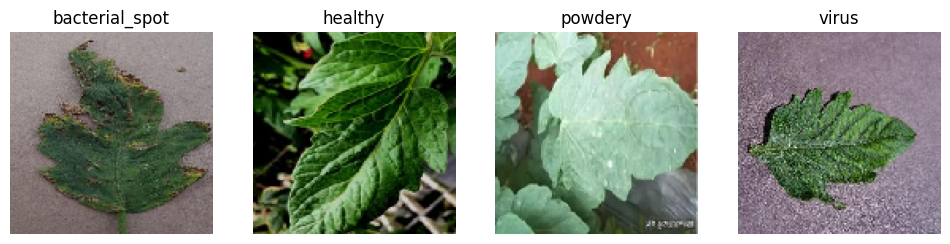

In [4]:
fig, axes = plt.subplots(1, len(classes), figsize=(12, 3))
for i, ax in enumerate(axes):
    ax.imshow(X[np.where(y == i)[0][0]].astype("uint8"))
    ax.set_title(classes[i])
    ax.axis("off")
plt.show()

### 2. Split Data
Split sama persis dengan tugas 9 (`random_state=42`) supaya perbandingannya adil.

In [5]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=42
)
print("Train:", X_train.shape, "Test:", X_test.shape)

Train: (224, 128, 128, 3) Test: (56, 128, 128, 3)


### 3. Arsitektur Model
Augmentasi yang dipakai sama untuk semua model. Fungsi `train` dipakai bersama supaya setting training (epoch, batch, early stopping) identik.

In [6]:
augment = keras.Sequential([
    keras.layers.RandomFlip("horizontal_and_vertical"),
    keras.layers.RandomRotation(0.1),
])

def train(model, lr=1e-3):
    model.compile(optimizer=keras.optimizers.Adam(lr), loss="sparse_categorical_crossentropy", metrics=["accuracy"])
    return model.fit(
        X_train, y_train,
        validation_split=0.2,
        epochs=40,
        batch_size=16,
        callbacks=[keras.callbacks.EarlyStopping(patience=8, restore_best_weights=True)],
    )

#### a. CNN from Scratch (model tugas 9)

In [7]:
keras.utils.set_random_seed(42)

cnn = keras.Sequential([
    keras.Input(shape=(img_size, img_size, 3)),
    keras.layers.Rescaling(1.0 / 255),
    augment,
    keras.layers.Conv2D(32, 3, activation="relu"),
    keras.layers.MaxPooling2D(),
    keras.layers.Conv2D(64, 3, activation="relu"),
    keras.layers.MaxPooling2D(),
    keras.layers.Conv2D(128, 3, activation="relu"),
    keras.layers.MaxPooling2D(),
    keras.layers.Flatten(),
    keras.layers.Dense(128, activation="relu"),
    keras.layers.Dropout(0.5),
    keras.layers.Dense(len(classes), activation="softmax"),
], name="cnn_scratch")
cnn.summary()

Model: "cnn_scratch"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ rescaling (Rescaling)           │ (None, 128, 128, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ sequential (Sequential)         │ (None, 128, 128, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d (Conv2D)                 │ (None, 126, 126, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 63, 63, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 61, 61, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 30, 30, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 28, 28, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 14, 14, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 25088)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │     3,211,392 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 4)              │           516 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 3,305,156 (12.61 MB)

 Trainable params: 3,305,156 (12.61 MB)

 Non-trainable params: 0 (0.00 B)

#### b. Transfer Learning MobileNetV2
Base model pretrained ImageNet dibekukan (`trainable=False`), lalu ditambah head `GlobalAveragePooling → Dropout → Dense softmax`.

In [8]:
keras.utils.set_random_seed(42)

base_mnet = keras.applications.MobileNetV2(
    input_shape=(img_size, img_size, 3), include_top=False, weights="imagenet"
)
base_mnet.trainable = False

inputs = keras.Input(shape=(img_size, img_size, 3))
x = augment(inputs)
x = keras.applications.mobilenet_v2.preprocess_input(x)  # skala ke [-1, 1]
x = base_mnet(x, training=False)
x = keras.layers.GlobalAveragePooling2D()(x)
x = keras.layers.Dropout(0.3)(x)
outputs = keras.layers.Dense(len(classes), activation="softmax")(x)
mobilenet = keras.Model(inputs, outputs, name="mobilenetv2_tl")
mobilenet.summary()

9406464/9406464 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step


Model: "mobilenetv2_tl"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_3 (InputLayer)      │ (None, 128, 128, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ sequential (Sequential)         │ (None, 128, 128, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ true_divide (TrueDivide)        │ (None, 128, 128, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ subtract (Subtract)             │ (None, 128, 128, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ mobilenetv2_1.00_128            │ (None, 4, 4, 1280)     │     2,257,984 │
│ (Functional)                    │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 1280)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 1280)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 4)              │         5,124 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,263,108 (8.63 MB)

 Trainable params: 5,124 (20.02 KB)

 Non-trainable params: 2,257,984 (8.61 MB)

#### c. Transfer Learning EfficientNetB0
Skema sama dengan MobileNetV2. EfficientNet di Keras sudah punya layer normalisasi sendiri, jadi input cukup 0-255.

In [9]:
keras.utils.set_random_seed(42)

base_eff = keras.applications.EfficientNetB0(
    input_shape=(img_size, img_size, 3), include_top=False, weights="imagenet"
)
base_eff.trainable = False

inputs = keras.Input(shape=(img_size, img_size, 3))
x = augment(inputs)
x = base_eff(x, training=False)
x = keras.layers.GlobalAveragePooling2D()(x)
x = keras.layers.Dropout(0.3)(x)
outputs = keras.layers.Dense(len(classes), activation="softmax")(x)
effnet = keras.Model(inputs, outputs, name="efficientnetb0_tl")
effnet.summary()

16705208/16705208 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step


Model: "efficientnetb0_tl"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_5 (InputLayer)      │ (None, 128, 128, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ sequential (Sequential)         │ (None, 128, 128, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ efficientnetb0 (Functional)     │ (None, 4, 4, 1280)     │     4,049,571 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d_1      │ (None, 1280)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 1280)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 4)              │         5,124 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 4,054,695 (15.47 MB)

 Trainable params: 5,124 (20.02 KB)

 Non-trainable params: 4,049,571 (15.45 MB)

### 4. Training

In [10]:
import time

models = {"CNN Scratch": cnn, "MobileNetV2": mobilenet, "EfficientNetB0": effnet}
histories, train_time = {}, {}
for name, m in models.items():
    print(f"\n===== {name} =====")
    t0 = time.time()
    histories[name] = train(m)
    train_time[name] = time.time() - t0


===== CNN Scratch =====
Epoch 1/40
12/12 ━━━━━━━━━━━━━━━━━━━━ 7s 92ms/step - accuracy: 0.3855 - loss: 1.2757 - val_accuracy: 0.4444 - val_loss: 1.1984
Epoch 2/40
12/12 ━━━━━━━━━━━━━━━━━━━━ 0s 27ms/step - accuracy: 0.6089 - loss: 0.9139 - val_accuracy: 0.2444 - val_loss: 1.7706
Epoch 3/40
12/12 ━━━━━━━━━━━━━━━━━━━━ 0s 27ms/step - accuracy: 0.6257 - loss: 0.8203 - val_accuracy: 0.5778 - val_loss: 0.7063
Epoch 4/40
12/12 ━━━━━━━━━━━━━━━━━━━━ 1s 26ms/step - accuracy: 0.8212 - loss: 0.5188 - val_accuracy: 0.8444 - val_loss: 0.4117
Epoch 5/40
12/12 ━━━━━━━━━━━━━━━━━━━━ 1s 28ms/step - accuracy: 0.8212 - loss: 0.4599 - val_accuracy: 0.8667 - val_loss: 0.3444
Epoch 6/40
12/12 ━━━━━━━━━━━━━━━━━━━━ 0s 31ms/step - accuracy: 0.8324 - loss: 0.4222 - val_accuracy: 0.9111 - val_loss: 0.3239
Epoch 7/40
12/12 ━━━━━━━━━━━━━━━━━━━━ 1s 23ms/step - accuracy: 0.8994 - loss: 0.3024 - val_accuracy: 0.9111 - val_loss: 0.2786
Epoch 8/40
12/12 ━━━━━━━━━━━━━━━━━━━━ 0s 21ms/step - accuracy: 0.8156 - loss: 0.5125 -

Grafik accuracy dan loss validasi tiap model

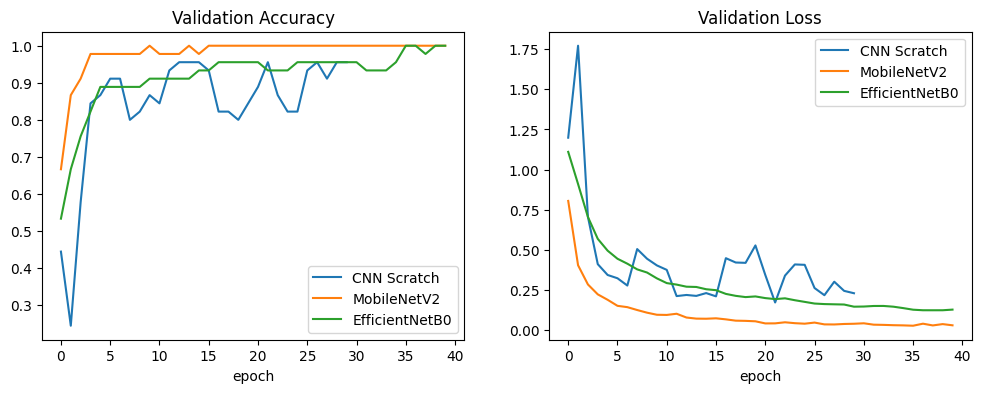

In [11]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4))
for name, h in histories.items():
    ax1.plot(h.history["val_accuracy"], label=name)
    ax2.plot(h.history["val_loss"], label=name)
ax1.set_title("Validation Accuracy")
ax1.set_xlabel("epoch")
ax1.legend()
ax2.set_title("Validation Loss")
ax2.set_xlabel("epoch")
ax2.legend()
plt.show()

### 5. Evaluasi
Accuracy, precision, recall, dan F1-score (weighted) di data test.

In [12]:
from sklearn.metrics import accuracy_score, precision_recall_fscore_support, classification_report, ConfusionMatrixDisplay

preds, rows = {}, {}
for name, m in models.items():
    preds[name] = m.predict(X_test, verbose=0).argmax(axis=1)
    acc = accuracy_score(y_test, preds[name])
    prec, rec, f1, _ = precision_recall_fscore_support(y_test, preds[name], average="weighted", zero_division=0)
    rows[name] = {
        "Accuracy": acc, "Precision": prec, "Recall": rec, "F1-Score": f1,
        "Trainable Params": sum(int(np.prod(w.shape)) for w in m.trainable_weights),
        "Epoch": len(histories[name].history["loss"]),
        "Waktu Training (s)": train_time[name],
    }

hasil = pd.DataFrame(rows).T
hasil.round(4)

,Accuracy,Precision,Recall,F1-Score,Trainable Params,Epoch,Waktu Training (s)
CNN Scratch,0.9643,0.9655,0.9643,0.9643,3305156.0,30.0,16.3870
MobileNetV2,1.0000,1.0000,1.0000,1.0000,5124.0,40.0,24.8104
EfficientNetB0,0.9643,0.9655,0.9643,0.9643,5124.0,40.0,35.4640


In [13]:
for name in models:
    print(f"===== {name} =====")
    print(classification_report(y_test, preds[name], target_names=classes, zero_division=0))

===== CNN Scratch =====
                precision    recall  f1-score   support

bacterial_spot       1.00      0.93      0.96        14
       healthy       0.93      1.00      0.97        14
       powdery       0.93      0.93      0.93        14
         virus       1.00      1.00      1.00        14

      accuracy                           0.96        56
     macro avg       0.97      0.96      0.96        56
  weighted avg       0.97      0.96      0.96        56

===== MobileNetV2 =====
                precision    recall  f1-score   support

bacterial_spot       1.00      1.00      1.00        14
       healthy       1.00      1.00      1.00        14
       powdery       1.00      1.00      1.00        14
         virus       1.00      1.00      1.00        14

      accuracy                           1.00        56
     macro avg       1.00      1.00      1.00        56
  weighted avg       1.00      1.00      1.00        56

===== EfficientNetB0 =====
                precisi

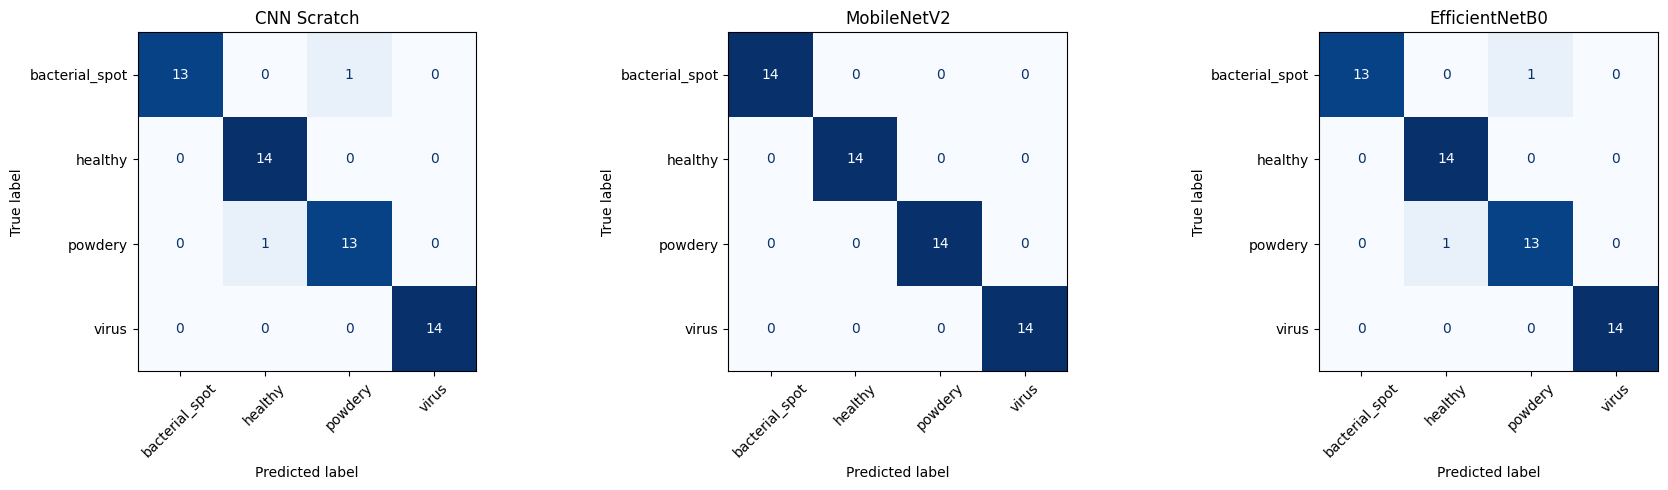

In [14]:
fig, axes = plt.subplots(1, len(models), figsize=(18, 5))
for ax, name in zip(axes, models):
    ConfusionMatrixDisplay.from_predictions(y_test, preds[name], display_labels=classes, cmap="Blues", ax=ax, colorbar=False)
    ax.set_title(name)
    ax.tick_params(axis="x", rotation=45)
plt.tight_layout()
plt.show()

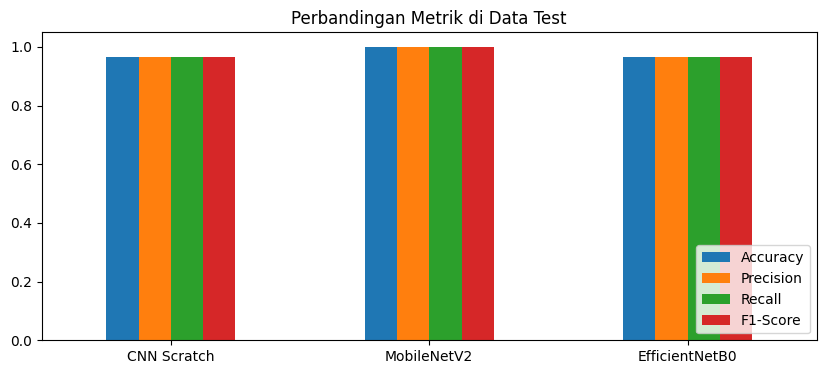

In [15]:
hasil[["Accuracy", "Precision", "Recall", "F1-Score"]].plot.bar(figsize=(10, 4), ylim=(0, 1.05), rot=0)
plt.title("Perbandingan Metrik di Data Test")
plt.legend(loc="lower right")
plt.show()

### 6. Report Perbandingan

In [16]:
terbaik = hasil["F1-Score"].astype(float).idxmax()
tl = hasil.loc[["MobileNetV2", "EfficientNetB0"]]
print(f"Model terbaik berdasarkan F1-Score : {terbaik} ({hasil.loc[terbaik, 'F1-Score']:.4f})")
print(f"Transfer learning terbaik          : {tl['F1-Score'].astype(float).idxmax()}")
print(f"Selisih F1 TL terbaik vs scratch    : {tl['F1-Score'].max() - hasil.loc['CNN Scratch', 'F1-Score']:+.4f}")

Model terbaik berdasarkan F1-Score : MobileNetV2 (1.0000)
Transfer learning terbaik          : MobileNetV2
Selisih F1 TL terbaik vs scratch    : +0.0357


**Kesimpulan**

Hasil evaluasi di data test (56 gambar, 14 per kelas):

| Model | Accuracy | Precision | Recall | F1-Score | Trainable Params | Epoch | Waktu (s) |
|---|---|---|---|---|---|---|---|
| CNN Scratch | 0.9643 | 0.9655 | 0.9643 | 0.9643 | 3.305.156 | 30 (early stop) | 16,4 |
| MobileNetV2 | **1.0000** | **1.0000** | **1.0000** | **1.0000** | 5.124 | 40 | 24,8 |
| EfficientNetB0 | 0.9643 | 0.9655 | 0.9643 | 0.9643 | 5.124 | 40 | 35,5 |

1. **Model terbaik adalah MobileNetV2** dengan accuracy, precision, recall, dan F1-score sempurna 1.0000. Seluruh 56 gambar test terklasifikasi benar, unggul +0.0357 F1 dibanding CNN scratch.
2. **EfficientNetB0 dan CNN scratch sama-sama mendapat F1 0.9643**, dengan pola kesalahan yang sama: masing-masing salah 2 gambar (1 `bacterial_spot` dan 1 `powdery` diprediksi sebagai kelas lain). Kelas `virus` diprediksi sempurna oleh ketiga model, sedangkan `powdery` menjadi kelas paling sulit untuk model selain MobileNetV2.
3. **Efisiensi parameter.** Kedua model transfer learning hanya melatih 5.124 parameter (head Dense), sekitar **645 kali lebih sedikit** dibanding CNN scratch yang melatih 3,3 juta parameter dari nol. Dengan parameter sekecil itu hasilnya tetap setara bahkan lebih baik, karena fitur visual (tepi, tekstur, warna bercak daun) sudah dipelajari dari ImageNet.
4. **Kestabilan training.** Kurva validasi CNN scratch naik-turun cukup tajam (val_accuracy sempat 0.96 lalu jatuh ke 0.80) dan berhenti di epoch 30 oleh early stopping. MobileNetV2 sudah mencapai val_accuracy 0.98 di epoch ke-4 dan stabil di 1.00 sejak epoch 16. EfficientNetB0 naik lebih perlahan namun stabil, dan baru mencapai 1.00 di akhir training. Ini menunjukkan transfer learning lebih cepat konvergen dan lebih stabil.
5. **Waktu training.** CNN scratch paling cepat dari sisi waktu (16 detik) karena arsitekturnya dangkal dan berhenti lebih awal, sedangkan model transfer learning tetap melakukan forward pass melalui base model yang dalam di setiap epoch. EfficientNetB0 paling lama (35 detik) karena arsitekturnya paling besar (4 juta parameter total). Kedua model TL menjalankan 40 epoch penuh karena val_loss masih terus turun, artinya hasilnya masih bisa meningkat bila epoch ditambah.
6. **MobileNetV2 vs EfficientNetB0.** Pada resolusi 128×128 MobileNetV2 lebih unggul. Salah satu sebabnya, MobileNetV2 memiliki bobot ImageNet yang memang dilatih pada resolusi 128, sedangkan EfficientNetB0 aslinya dilatih pada 224×224 sehingga fiturnya kurang optimal di resolusi kecil.
7. **Catatan perbandingan dengan tugas 9.** Pada tugas 9 CNN scratch mendapat F1 0.9119, sedangkan di sini 0.9643 dengan split data yang sama. Perbedaan ini wajar karena training from scratch sensitif terhadap inisialisasi bobot acak dan urutan data, yang justru memperlihatkan kelemahan training from scratch pada dataset kecil.

Secara keseluruhan, untuk dataset kecil seperti ini (280 gambar), **transfer learning lebih unggul**: akurasi lebih tinggi atau setara, parameter yang dilatih jauh lebih sedikit, dan training lebih stabil. Peningkatan yang bisa dicoba selanjutnya adalah menambah epoch, fine-tuning beberapa layer terakhir base model dengan learning rate kecil (mis. `1e-5`), dan memakai input 224×224 untuk EfficientNetB0.